In [5]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import GWFish.modules as gw
import gc
import torch
from dingo.core.posterior_models.build_model import build_model_from_kwargs
import pandas as pd
from dingo.gw.inference.sampler import GWComposedSampler
import dingo.gw.injection as injection
from dingo.gw.noise.asd_dataset import ASDDataset


os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # use GPU 1
waveform_model = 'IMRPhenomXPHM'
f_ref = 20.
detectors = ['ET']
network = gw.detection.Network(detector_ids = detectors, detection_SNR = (0., 8.))


/home/tpausch/.conda/envs/ET-DINGO/lib/python3.10/site-packages/lalsimulation/_lalsimulation_swig.py:8: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## Define functions

In [2]:
def simulate_injections(name, num_injections):

    pm = build_model_from_kwargs(
        filename=f"/scratch/tpausch/models/{name}/model_latest.pt",
        device="cuda",
        load_training_info=False,
    )

    
    out_dir = f"/scratch/tpausch/test_data/{name}/injections"
    os.makedirs(out_dir, exist_ok=True)

    np.random.seed(42)  # optional, for reproducibility

    injection_generator = injection.Injection.from_posterior_model_metadata(
        pm.metadata
    )

    asd_fname = "/scratch/tpausch/ASD/asds_ET_T8.hdf5"
    asd_dataset = ASDDataset(file_name=asd_fname)

    injection_generator.asd = {
        k: v[0] for k, v in asd_dataset.asds.items()
    }

    # This is the combined intrinsic + extrinsic bilby PriorDict
    # that the network was trained on
    prior = injection_generator.prior
    print(prior)

    # ============================================================
    # Draw and run injections
    # ============================================================

    for idx in range(num_injections):

        print(f"Running injection {idx}")

        theta = prior.sample()
        theta = {k: float(v) for k, v in theta.items()}  # cast numpy -> float

        strain_data = injection_generator.injection(theta)

        payload = {
            "theta_true": theta,
            "strain_data": strain_data,
        }

        fname = os.path.join(out_dir, f"inj_{idx:04d}.pkl")

        with open(fname, "wb") as f:
            pickle.dump(payload, f)

    print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
    print(torch.cuda.memory_reserved() / 1e9, "GB reserved")
    del pm
    gc.collect()
    torch.cuda.empty_cache()
    return 1 

In [3]:
def infere_parameters(name, injection_name, stage):


    pm = build_model_from_kwargs(
        filename=f"/scratch/tpausch/models/{name}/model_latest.pt",
        device="cuda",
        load_training_info=False,
    )

    os.makedirs(f"/scratch/tpausch/test_data/{stage}/results", exist_ok=True)

    injection_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{injection_name}/injections"))

    for fname in injection_files:

        # --------------------------------------------------------
        # Load injection
        # --------------------------------------------------------

        with open(f"/scratch/tpausch/test_data/{injection_name}/injections/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]
        strain_data = payload["strain_data"]

        # --------------------------------------------------------
        # Run sampler
        # --------------------------------------------------------

        sampler = GWComposedSampler.from_model(pm, strain_data)
    
    
        sampler.run_sampler(
            num_samples=5_000,
            batch_size=5_000,
        )
    
        result = sampler.to_result()




        # --------------------------------------------------------
        # calculate network SNR
        # --------------------------------------------------------
        parameters = pd.DataFrame(
            {key: np.array([np.asarray(val).item()]) for key, val in theta_true.items()}
        )
        snr_df = gw.utilities.get_snr(parameters, network, waveform_model, f_ref)
        network_snr = float(snr_df["network"].iloc[0])  # extract as plain float

        # --------------------------------------------------------
        # Store result
        # --------------------------------------------------------

        result_payload = {
            "theta_true": theta_true,
            "result": result,
            "network_snr": network_snr,
        }

        outname = fname.replace("inj_", "result_")

        with open(f"/scratch/tpausch/test_data/{stage}/results/{outname}", "wb") as f:
            pickle.dump(result_payload, f)

        print(f"Saved /scratch/tpausch/test_data/{stage}/results/{outname}")

    print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
    print(torch.cuda.memory_reserved() / 1e9, "GB reserved")
    del pm
    gc.collect()
    torch.cuda.empty_cache()
    return 1  # only the results survive, pm is freed on return

In [4]:
import shutil


def sort_by_chirpmass_stage1(name):
    

    stage_2_models= ["75_150", "600_975"]

    for model in stage_2_models:
        create_dir = f"/scratch/tpausch/test_data/{model}/injections"
        os.makedirs(create_dir, exist_ok=True)
    
    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    i=0
    j=0
    for fname in result_files:
        
        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)
            theta_true = payload["theta_true"]
        result = payload["result"]

        posterior_samples = result.samples
        cm_samples = np.array(posterior_samples["chirp_mass"])
        cm_median = np.median(cm_samples)


        #print (cm_mean)

        fname = fname.replace( "result_", "inj_")

        #copy injection file to new directory
      
        if 100 <= cm_median <= 125:
            #copy injection file to new directory
            shutil.copy(f"/scratch/tpausch/test_data/{name}/injections/{fname}", f"/scratch/tpausch/test_data/75_150/injections/{fname}")
            i+=1
            print (cm_median)
        elif 725 <= cm_median <= 850:
            shutil.copy(f"/scratch/tpausch/test_data/{name}/injections/{fname}", f"/scratch/tpausch/test_data/600_975/injections/{fname}")
            j+=1
            print (cm_median)
        
    print (i)
    print (j)  
    #out_dir = f"/scratch/tpausch/test_data/{name}/injections"
    #os.makedirs(out_dir, exist_ok=True)
    

In [5]:
def plot_chirpmass_error(stage):

    true_cm = []
    true_mr = []
    mass_ratio_error = []
    mass_ratio_std = []
    chirp_mass_error = []
    chirp_mass_std = []



    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{stage}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{stage}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]
        result = payload["result"]

        posterior_samples = result.samples

        #q_samples = np.array(posterior_samples["mass_ratio"])

        # inference statistics
        #q_mean = np.mean(q_samples)
        #q_std = np.std(q_samples)
    #
        #true_q = theta_true["mass_ratio"]

        cm_samples = np.array(posterior_samples["chirp_mass"])

        cm_mean = np.mean(cm_samples)
        cm_std = np.std(cm_samples)

        true_mr.append(theta_true["mass_ratio"])
        true_cm.append(theta_true["chirp_mass"])
        #mass_ratio_error.append(q_mean - true_q)
        #mass_ratio_std.append(q_std)
        chirp_mass_error.append(cm_mean - theta_true["chirp_mass"])
        chirp_mass_std.append(cm_std)


    true_mr = np.array(true_mr)
    true_cm = np.array(true_cm)

    # ------------------------------------------------------------
    # Error bars
    # ------------------------------------------------------------

    #plt.errorbar(
    #    true_cm,
    #    chirp_mass_error,
    #    yerr=chirp_mass_std,
    #    fmt="none",
    #    capsize=4,
    #    alpha=0.5,
    #    color="gray",
    #)

    # ------------------------------------------------------------
    # Colored scatter points
    # ------------------------------------------------------------

    sc = plt.scatter(
        true_cm,
        chirp_mass_error,
        s=20,
        edgecolor="black",
        alpha=0.3
    )

    # ------------------------------------------------------------
    # Reference line
    # ------------------------------------------------------------

    plt.axhline(0, linestyle="--", color="black")


    # ------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------

    plt.xlabel("True chirp mass")
    plt.ylabel("Chirp mass inference error (inferred − true)")

    plt.title("Chirp-mass inference error")

    plt.grid(True)

    plt.tight_layout()
    plt.show()

    cm_err = np.asarray(chirp_mass_error)

    mean_error = np.mean(cm_err)          # signed average bias (over/under-estimation)
    mean_abs_error = np.mean(np.abs(cm_err))  # average magnitude of deviation
    rms_error = np.sqrt(np.mean(cm_err**2))   # RMS deviation, penalizes outliers more
    std_error = np.std(cm_err)            # spread of the errors around their mean
    p80_abs_error = np.percentile(np.abs(cm_err), 80)
    p90_abs_error = np.percentile(np.abs(cm_err), 90)
    #p95_abs_error = np.percentile(np.abs(cm_err), 95)
    #p98_abs_error = np.percentile(np.abs(cm_err), 98)
    #p99_abs_error = np.percentile(np.abs(cm_err), 99)


    print(f"Mean error (bias):      {mean_error:.3f}")
    print(f"Mean absolute error:    {mean_abs_error:.3f}")
    print(f"RMS error:              {rms_error:.3f}")
    print(f"Std of error:           {std_error:.3f}")
    print(f"80th percentile |error|: {p80_abs_error:.3f}")
    print(f"90th percentile |error|: {p90_abs_error:.3f}")
    #print(f"95th percentile |error|: {p95_abs_error:.3f}")
    #print(f"98th percentile |error|: {p98_abs_error:.3f}")
    #print(f"99th percentile |error|: {p99_abs_error:.3f}")

In [6]:
def scatter_chirpmass(name, min, max):
    CM_MIN, CM_MAX = min, max
    true_cm = []
    true_mr = []
    mass_ratio_error = []
    mass_ratio_std = []
    chirp_mass_error = []
    chirp_mass_std = []


    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]

          # --- filter on true chirp mass ---
        true_chirp_mass = theta_true["chirp_mass"]
        

        result = payload["result"]

        posterior_samples = result.samples


        cm_samples = np.array(posterior_samples["chirp_mass"])

        cm_median = np.median(cm_samples)
        cm_std = np.std(cm_samples)

        if not (CM_MIN <= cm_median <= CM_MAX):
                    continue

        true_mr.append(theta_true["mass_ratio"])
        true_cm.append(theta_true["chirp_mass"])
        #mass_ratio_error.append(q_mean - true_q)
        #mass_ratio_std.append(q_std)
        chirp_mass_error.append(cm_median - theta_true["chirp_mass"])
        chirp_mass_std.append(cm_std)


    true_mr = np.array(true_mr)
    true_cm = np.array(true_cm)

    # ------------------------------------------------------------
    # Error bars
    # ------------------------------------------------------------

    #plt.errorbar(
    #    true_cm,
    #    chirp_mass_error,
    #    yerr=chirp_mass_std,
    #    fmt="none",
    #    capsize=4,
    #    alpha=0.5,
    #    color="gray",
    #)

    # ------------------------------------------------------------
    # Colored scatter points
    # ------------------------------------------------------------

    sc = plt.scatter(
        true_cm,
        chirp_mass_error,
        s=20,
        edgecolor="black",
        alpha=0.3
    )

    # ------------------------------------------------------------
    # Reference line
    # ------------------------------------------------------------

    plt.axhline(0, linestyle="--", color="black")


    # ------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------

    plt.xlabel("True chirp mass")
    plt.ylabel("Chirp mass inference error (inferred − true)")

    plt.title("Chirp-mass inference error")

    plt.grid(True)

    plt.tight_layout()
    plt.show()

    cm_err = np.asarray(chirp_mass_error)

    mean_error = np.mean(cm_err)          # signed average bias (over/under-estimation)
    mean_abs_error = np.mean(np.abs(cm_err))  # average magnitude of deviation
    rms_error = np.sqrt(np.mean(cm_err**2))   # RMS deviation, penalizes outliers more
    std_error = np.std(cm_err)            # spread of the errors around their mean
    p80_abs_error = np.percentile(np.abs(cm_err), 80)
    p90_abs_error = np.percentile(np.abs(cm_err), 90)
    #p95_abs_error = np.percentile(np.abs(cm_err), 95)
    #p98_abs_error = np.percentile(np.abs(cm_err), 98)
    #p99_abs_error = np.percentile(np.abs(cm_err), 99)


    print(len(cm_err), "samples in range", CM_MIN, "-", CM_MAX)
    print(f"Mean error (bias):      {mean_error:.3f}")
    print(f"Mean absolute error:    {mean_abs_error:.3f}")
    print(f"RMS error:              {rms_error:.3f}")
    print(f"Std of error:           {std_error:.3f}")
    print(f"80th percentile |error|: {p80_abs_error:.3f}")
    print(f"90th percentile |error|: {p90_abs_error:.3f}")
    #print(f"95th percentile |error|: {p95_abs_error:.3f}")
    #print(f"98th percentile |error|: {p98_abs_error:.3f}")
    #print(f"99th percentile |error|: {p99_abs_error:.3f}")
    return 0

## Stage 1

In [7]:
model_name="stage1"
injection_name= "stage1"
stage = "stage1"
num_injections = 1000
#simulate_injections(model_name, num_injections)
#infere_parameters(model_name, injection_name, stage)
sort_by_chirpmass_stage1(model_name)

730.2146


801.0773
732.01514
783.3843


844.3823
849.80817
839.61633
780.26807
845.5754


764.8838
820.27563
812.03754
778.6422


830.65204
844.4689
785.1433


...

845.00854
776.84
803.5092
803.7335


740.03314
811.9127
837.3602
775.31647
773.32745
755.91644


848.44165
818.77454
831.00635
805.75305


727.899
834.96686
813.28625


784.58124
804.7936
764.54016
5
224


# Stage 2


In [8]:
%%capture  
#stage = "stage2"
#stage_2_models= ["75_150", "600_975"]
#for model_name in stage_2_models:
#    infere_parameters(model_name, model_name, stage)

In [9]:
def scatter_chirpmass_comparison(name1, name2, min=0, max=1000):
    CM_MIN, CM_MAX = min, max
    name=name1
    true_cm1 = []
    true_cm2 = []
    chirp_mass_error1 = []
    chirp_mass_error2 = []
    chirp_mass_std = []


    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]

          # --- filter on true chirp mass ---
        true_chirp_mass = theta_true["chirp_mass"]
        

        result = payload["result"]

        posterior_samples = result.samples


        cm_samples = np.array(posterior_samples["chirp_mass"])

        cm_median = np.median(cm_samples)
        cm_std = np.std(cm_samples)

        


        true_cm1.append(theta_true["chirp_mass"])
        #mass_ratio_error.append(q_mean - true_q)
        #mass_ratio_std.append(q_std)
        chirp_mass_error1.append(cm_median - theta_true["chirp_mass"])
        chirp_mass_std.append(cm_std)




    true_cm1 = np.array(true_cm1)


    for fname in result_files:
    
            with open(f"/scratch/tpausch/test_data/{name2}/results/{fname}", "rb") as f:
                payload = pickle.load(f)
    
            theta_true = payload["theta_true"]
    
              # --- filter on true chirp mass ---
            true_chirp_mass = theta_true["chirp_mass"]
            
    
            result = payload["result"]
    
            posterior_samples = result.samples
    
    
            cm_samples = np.array(posterior_samples["chirp_mass"])
    
            cm_median = np.median(cm_samples)
            cm_std = np.std(cm_samples)
    
            
    
        
            true_cm2.append(theta_true["chirp_mass"])
            #mass_ratio_error.append(q_mean - true_q)
            #mass_ratio_std.append(q_std)
            chirp_mass_error2.append(cm_median - theta_true["chirp_mass"])
            chirp_mass_std.append(cm_std)
    
    


    true_cm2 = np.array(true_cm2)

    # ------------------------------------------------------------
    # Error bars
    # ------------------------------------------------------------

    #plt.errorbar(
    #    true_cm,
    #    chirp_mass_error,
    #    yerr=chirp_mass_std,
    #    fmt="none",
    #    capsize=4,
    #    alpha=0.5,
    #    color="gray",
    #)

    # ------------------------------------------------------------
    # Colored scatter points
    # ------------------------------------------------------------

    # ------------------------------------------------------------
    # Scatter plot: Two datasets
    # ------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(8, 6))

    # First dataset
    ax.scatter(
        true_cm1,
        chirp_mass_error1,
        s=20,
        color="tab:blue",
        edgecolor="black",
        alpha=0.3,
        label="Dataset 1"
    )

    # Second dataset
    ax.scatter(
        true_cm2,
        chirp_mass_error2,
        s=20,
        color="tab:orange",
        edgecolor="black",
        alpha=0.3,
        label="Dataset 2"
    )

    # ------------------------------------------------------------
    # Reference line
    # ------------------------------------------------------------

    ax.axhline(
        0,
        linestyle="--",
        color="black"
    )

    # ------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------

    ax.set_xlabel("True chirp mass")
    ax.set_ylabel("Chirp mass inference error (inferred − true)")

    ax.set_title("Chirp-mass inference error")

    ax.grid(True)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # Error statistics: Dataset 1
    # ------------------------------------------------------------

    cm_err1 = np.asarray(chirp_mass_error1)

    mean_error1 = np.mean(cm_err1)
    mean_abs_error1 = np.mean(np.abs(cm_err1))
    rms_error1 = np.sqrt(np.mean(cm_err1**2))
    std_error1 = np.std(cm_err1)

    p80_abs_error1 = np.percentile(np.abs(cm_err1), 80)
    p90_abs_error1 = np.percentile(np.abs(cm_err1), 90)

    print("\nDataset 1")
    print(len(cm_err1), "samples in range", CM_MIN, "-", CM_MAX)
    print(f"Mean error (bias):       {mean_error1:.3f}")
    print(f"Mean absolute error:     {mean_abs_error1:.3f}")
    print(f"RMS error:               {rms_error1:.3f}")
    print(f"Std of error:            {std_error1:.3f}")
    print(f"80th percentile |error|: {p80_abs_error1:.3f}")
    print(f"90th percentile |error|: {p90_abs_error1:.3f}")

    # ------------------------------------------------------------
    # Error statistics: Dataset 2
    # ------------------------------------------------------------

    cm_err2 = np.asarray(chirp_mass_error2)

    mean_error2 = np.mean(cm_err2)
    mean_abs_error2 = np.mean(np.abs(cm_err2))
    rms_error2 = np.sqrt(np.mean(cm_err2**2))
    std_error2 = np.std(cm_err2)

    p80_abs_error2 = np.percentile(np.abs(cm_err2), 80)
    p90_abs_error2 = np.percentile(np.abs(cm_err2), 90)

    print("\nDataset 2")
    print(len(cm_err2), "samples in range", CM_MIN, "-", CM_MAX)
    print(f"Mean error (bias):       {mean_error2:.3f}")
    print(f"Mean absolute error:     {mean_abs_error2:.3f}")
    print(f"RMS error:               {rms_error2:.3f}")
    print(f"Std of error:            {std_error2:.3f}")
    print(f"80th percentile |error|: {p80_abs_error2:.3f}")
    print(f"90th percentile |error|: {p90_abs_error2:.3f}")

    return 0


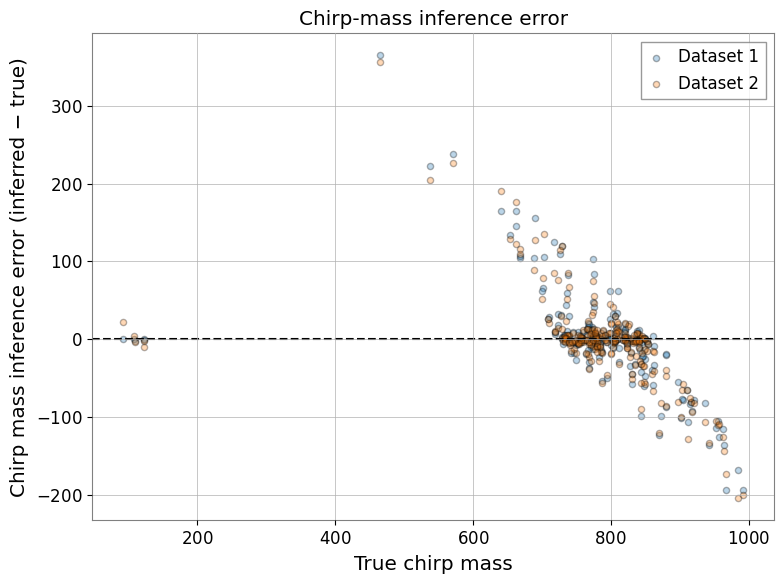


Dataset 1
229 samples in range 0 - 1000
Mean error (bias):       -0.117
Mean absolute error:     33.318
RMS error:               61.113
Std of error:            61.113
80th percentile |error|: 59.370
90th percentile |error|: 105.525

Dataset 2
229 samples in range 0 - 1000
Mean error (bias):       -1.587
Mean absolute error:     34.218
RMS error:               60.813
Std of error:            60.792
80th percentile |error|: 56.913
90th percentile |error|: 106.801


0

In [10]:
scatter_chirpmass_comparison("stage2", "stage1")

# Importance Sampling


In [11]:
def importance_sampling(
    name,
    injection_name,
    stage,
    importance_sampling_processes=12,
):

    pm = build_model_from_kwargs(
        filename=f"/scratch/tpausch/models/{name}/model_latest.pt",
        device="cuda",
        load_training_info=False,
    )

    results_dir = f"/scratch/tpausch/test_data/{stage}/results"
    injections_dir = (
        f"/scratch/tpausch/test_data/{injection_name}/injections"
    )

    os.makedirs(results_dir, exist_ok=True)

    injection_files = sorted(os.listdir(injections_dir))

    ess=[]
    for fname in injection_files:  

        # --------------------------------------------------------
        # Load injection
        # --------------------------------------------------------

        with open(f"{injections_dir}/{fname}", "rb") as f:
            payload = pickle.load(f)

        theta_true = payload["theta_true"]
        strain_data = payload["strain_data"]

        # --------------------------------------------------------
        # Run DINGO sampler
        # --------------------------------------------------------

        sampler = GWComposedSampler.from_model(pm, strain_data)

        sampler.run_sampler(
            num_samples=5_000,
            batch_size=5_000,
        )

        result = sampler.to_result()

        # --------------------------------------------------------
        # Check that the proposal density is available
        # --------------------------------------------------------

        if "log_prob" not in result.samples.columns:
            raise RuntimeError(
                f"Cannot importance-sample {fname}: "
                "the samples do not contain log_prob. "
                "Density recovery is required for density-free samplers."
            )

        # --------------------------------------------------------
        # Recover marginalized phase parameters if necessary
        # --------------------------------------------------------

        # Use this when phase and/or psi were marginalized out
        # during training, rather than fixed to specific values.
        if (
            "phase" not in result.samples.columns
            or "psi" not in result.samples.columns
        ):
            result.sample_proposal_extensions(
                synthetic_parameters_kwargs={
                    "num_processes": importance_sampling_processes,
                }
            )

        # --------------------------------------------------------
        # Importance sampling
        # --------------------------------------------------------

        result.importance_sample(
            num_processes=importance_sampling_processes,
        )

        # --------------------------------------------------------
        # Importance-sampling diagnostics
        # --------------------------------------------------------

        result.print_summary()

        log_evidence = float(result.log_evidence)
        n_eff = float(result.n_eff)
        sample_efficiency = float(result.sample_efficiency)
        ess.append(sample_efficiency)

        # --------------------------------------------------------
        # Calculate network SNR
        # --------------------------------------------------------

        parameters = pd.DataFrame(
            {
                key: np.array([np.asarray(val).item()])
                for key, val in theta_true.items()
            }
        )

        snr_df = gw.utilities.get_snr(
            parameters,
            network,
            waveform_model,
            f_ref,
        )

        network_snr = float(snr_df["network"].iloc[0])

        # --------------------------------------------------------
        # Store result, including importance-sampling diagnostics
        # --------------------------------------------------------

        result_payload = {
            "theta_true": theta_true,
            "result": result,
            "network_snr": network_snr,
            "log_evidence": log_evidence,
            "n_eff": n_eff,
            "sample_efficiency": sample_efficiency,
        }

        outname = fname.replace("inj_", "result_")
        outpath = f"{results_dir}/{outname}"

        with open(outpath, "wb") as f:
            pickle.dump(result_payload, f)

        print(f"Saved {outpath}")
        print(f"  Network SNR:       {network_snr:.2f}")
        print(f"  Log evidence:      {log_evidence:.3f}")
        print(f"  Effective samples: {n_eff:.1f}")
        print(f"  Sample efficiency: {sample_efficiency:.4f}")

    print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
    print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

    del pm
    gc.collect()
    torch.cuda.empty_cache()

    return 0

In [12]:
%%capture  
importance_sampling(
    name="stage1",
    injection_name="600_975",
    stage="stage1_importance_sampling",
    
)

importance_sampling(
    name="600_975",
    injection_name="600_975",
    stage="stage2_importance_sampling",
)

In [24]:
def get_ess_old(name):
    ess=[]
    result_files = sorted(os.listdir(f"/scratch/tpausch/test_data/{name}/results"))

    for fname in result_files:

        with open(f"/scratch/tpausch/test_data/{name}/results/{fname}", "rb") as f:
            payload = pickle.load(f)
        result = payload["result"]

        efficiency = result.sample_efficiency
        print(result.sample_efficiency)
        ess.append(efficiency)


    return ess

In [27]:
get_ess_old("stage2_importance_sampling")

0.0038852307827454227
0.0383752309933121
0.007987179584345444
0.004574128252645351
0.00039983819302879755
0.010310862492545331
0.0788158094680052
0.021582406757002917
0.03970515543971674
0.04621823646778262
0.12687708546066342
0.169390512190547
0.038027578937456806
0.0786489610937601
0.0033798711239116912
0.4334898164474127
0.06464866537399377
0.0021106931974139856
0.053754638682206056
0.0006069456310070721
0.00020006009193321547
0.0002001645813172034
0.20382395049338034
0.0020113532302011164
0.014304692199074669
0.031089222137969955
0.0237246356032127
0.005460033886067571
0.026425248797912654
0.0002
0.018388867339702977


KeyboardInterrupt: 

In [29]:
import os
import pickle
import numpy as np
import pandas as pd


def get_ess(name, base_dir="/scratch/tpausch/test_data"):
    rows = []
    results_dir = f"{base_dir}/{name}/results"

    for fname in sorted(os.listdir(results_dir)):
        with open(f"{results_dir}/{fname}", "rb") as f:
            payload = pickle.load(f)

        result = payload["result"]
        rows.append({
            "file": fname,
            "sample_efficiency": result.sample_efficiency,
            "snr": payload["network_snr"],
        })
        #print(result.sample_efficiency)

    return pd.DataFrame(rows)


def compare_ess(df1, df2, snr_rtol=0.01):
    """
    Compare two DataFrames from get_ess.

    Returns a DataFrame with ess1/ess2 per file and a flag whether the
    SNRs agree within snr_rtol (default 1%, i.e. they match to >= 99%).
    Rows are aligned by file name.
    """
    merged = df1.merge(df2, on="file", suffixes=("_1", "_2"), how="inner")

    n_dropped = max(len(df1), len(df2)) - len(merged)
    if n_dropped > 0:
        print(f"Warning: {n_dropped} file(s) without a counterpart were dropped.")

    out = pd.DataFrame({
        "file": merged["file"],
        "snr_1": merged["snr_1"],
        "snr_2": merged["snr_2"],
        "ess_ratio": merged["sample_efficiency_1"] / merged["sample_efficiency_2"],
    })

    # relative SNR deviation, referenced to snr_2
    out["snr_rel_diff"] = (out["snr_1"] - out["snr_2"]).abs() / out["snr_2"].abs()
    out["snr_match"] = out["snr_rel_diff"] <= snr_rtol

    print(f"SNR matches (>=99%): {out['snr_match'].sum()}/{len(out)}")
    return out

In [30]:
df_a = get_ess("stage2_importance_sampling")
df_b = get_ess("stage1_importance_sampling")
cmp = compare_ess(df_a, df_b)
print(cmp)
print(cmp.loc[cmp["snr_match"], "ess_ratio"].describe())

SNR matches (>=99%): 224/224
                file        snr_1        snr_2  ess_ratio  snr_rel_diff  \
0    result_0011.pkl  1052.208163  1052.208163   6.891254           0.0   
1    result_0023.pkl   157.601363   157.601363   9.879904           0.0   
2    result_0030.pkl    58.112087    58.112087   3.985067           0.0   
3    result_0031.pkl   104.643828   104.643828   0.831394           0.0   
4    result_0043.pkl   240.666864   240.666864   0.663744           0.0   
..               ...          ...          ...        ...           ...   
219  result_0980.pkl    47.327570    47.327570   8.091254           0.0   
220  result_0981.pkl     7.156678     7.156678   0.902889           0.0   
221  result_0990.pkl   222.078949   222.078949   1.967944           0.0   
222  result_0994.pkl    94.835265    94.835265  31.295349           0.0   
223  result_0996.pkl    35.138685    35.138685   4.641316           0.0   

     snr_match  
0         True  
1         True  
2         True  
3 

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def compare_ess(df1, df2, snr_rtol=0.01, label1="run 1", label2="run 2",
                ess_threshold=1.0, top_frac=0.05, plot=True):
    """
    Compare two DataFrames from get_ess.

    Prints: SNR match count, mean ESS ratio, number of events with
    ess > ess_threshold, and the top `top_frac` of ESS values per run.
    """
    merged = df1.merge(df2, on="file", suffixes=("_1", "_2"), how="inner")

    n_dropped = max(len(df1), len(df2)) - len(merged)
    if n_dropped > 0:
        print(f"Warning: {n_dropped} file(s) without a counterpart were dropped.")

    out = pd.DataFrame({
        "file": merged["file"],
        "snr_1": merged["snr_1"],
        "snr_2": merged["snr_2"],
        "ess_1": merged["sample_efficiency_1"],
        "ess_2": merged["sample_efficiency_2"],
    })
    out["ess_ratio"] = out["ess_1"] / out["ess_2"]
    out["snr_rel_diff"] = (out["snr_1"] - out["snr_2"]).abs() / out["snr_2"].abs()
    out["snr_match"] = out["snr_rel_diff"] <= snr_rtol

    # --- ratio statistics ---
    finite_ratio = out["ess_ratio"].replace([np.inf, -np.inf], np.nan).dropna()
    n_bad = len(out) - len(finite_ratio)

    print(f"SNR matches (>= {100 * (1 - snr_rtol):.0f}%): {out['snr_match'].sum()}/{len(out)}")
    print(f"Mean ESS ratio ({label1}/{label2}): {finite_ratio.mean():.4f}"
          f"  (median: {finite_ratio.median():.4f}, n={len(finite_ratio)})")
    if n_bad > 0:
        print(f"  ({n_bad} event(s) with inf/NaN ratio excluded from the mean)")

    matched = out.loc[out["snr_match"], "ess_ratio"].replace([np.inf, -np.inf], np.nan).dropna()
    if 0 < len(matched) < len(out):
        print(f"Mean ESS ratio, SNR-matched events only: {matched.mean():.4f} (n={len(matched)})")

    # --- ESS > threshold and top 5 % per run ---
    n_top = max(1, int(np.ceil(top_frac * len(out))))
    for col, label in [("ess_1", label1), ("ess_2", label2)]:
        n_above = (out[col] > ess_threshold).sum()
        print(f"\n[{label}] events with ESS > {ess_threshold}: {n_above}/{len(out)}")

        top = out.nlargest(n_top, col)
        q = out[col].quantile(1 - top_frac)
        print(f"[{label}] top {top_frac:.0%} of ESS ({n_top} events): "
              f"{100 * (1 - top_frac):.0f}th percentile = {q:.4f}, "
              f"mean of top = {top[col].mean():.4f}")
        print(top[["file", col, "snr_1" if col == "ess_1" else "snr_2"]].to_string(index=False))

    # --- plot ---
    if plot:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.scatter(out["snr_1"], out["ess_1"], c="tab:blue", alpha=0.7, label=label1)
        ax.scatter(out["snr_2"], out["ess_2"], c="tab:orange", alpha=0.7, label=label2)
        ax.set_xlabel("Network SNR")
        ax.set_ylabel("Sample efficiency")
        ax.set_yscale("log")
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()
        plt.show()

    return out

SNR matches (>= 99%): 224/224
Mean ESS ratio (stage2/stage1): 4.3619  (median: 2.4669, n=224)

[stage2] events with ESS > 1.0: 0/224
[stage2] top 5% of ESS (12 events): 95th percentile = 0.3092, mean of top = 0.3903
           file    ess_1      snr_1
result_0279.pkl 0.467602  50.829109
result_0086.pkl 0.433490  38.607183
result_0565.pkl 0.429955  62.583894
result_0307.pkl 0.423124  28.009729
result_0891.pkl 0.419171  67.301359
result_0578.pkl 0.399684 106.913165
result_0753.pkl 0.373934   4.685362
result_0642.pkl 0.369760  32.671135
result_0929.pkl 0.369478   8.315736
result_0297.pkl 0.356243  51.123802
result_0546.pkl 0.331376  10.476619
result_0262.pkl 0.309496  23.394630

[stage1] events with ESS > 1.0: 0/224
[stage1] top 5% of ESS (12 events): 95th percentile = 0.1408, mean of top = 0.1836
           file    ess_2     snr_2
result_0877.pkl 0.295278  6.716256
result_0753.pkl 0.210381  4.685362
result_0565.pkl 0.201069 62.583894
result_0279.pkl 0.196692 50.829109
result_0262.pkl 0.1

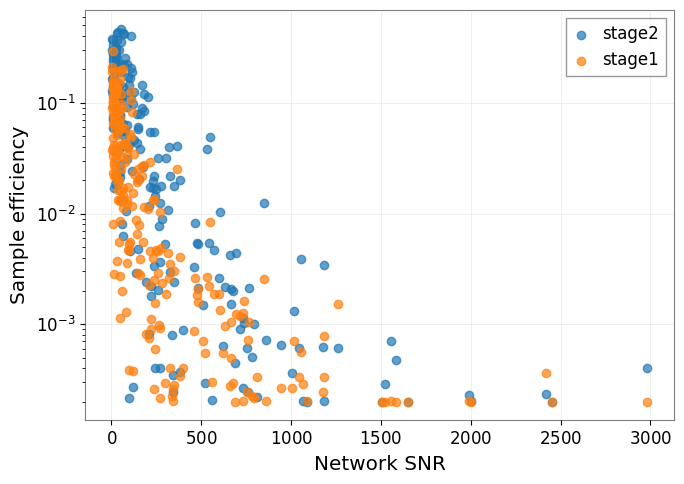

In [34]:
cmp = compare_ess(df_a, df_b, label1="stage2", label2="stage1")